# 🚀 Clase Práctica: Proceso ETL con Python y Análisis Exploratorio (EDA)

**Objetivo:** Aprender a Extraer, Transformar (limpiar y explorar) y Cargar datos desde cero, aplicando buenas prácticas de la industria como la trazabilidad (logging) y el uso de formatos modernos.

**Autor:** [Tu Nombre]  
**Fecha:** Octubre 2026

## 🏗️ Paso 0: Extracción de Datos Reales desde una API
En lugar de un archivo estático, consumiremos una API real (`Fake Store API`). 
Posteriormente, aplicaremos un proceso de "ensuciamiento controlado" para simular los problemas típicos que un ingeniero de datos encuentra en la vida real: duplicados, nulos, inconsistencia de texto y formatos de fecha mixtos.

In [12]:
import logging
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import requests
import random
from datetime import datetime, timedelta

# 1. EXTRAER DATOS REALES DE UNA API
print("📡 Conectando con la API real...")
response = requests.get("https://fakestoreapi.com/products")
data_real = response.json()

# Convertimos a DataFrame y aplanamos un poco la estructura
df_real = pd.json_normalize(data_real)
df_real = df_real[['id', 'title', 'category', 'price', 'description']]

# Renombramos columnas para que se parezcan a un dataset de ventas
df_real = df_real.rename(columns={
    'id': 'id_producto',
    'title': 'nombre_producto',
    'category': 'categoria',
    'price': 'precio',
    'description': 'descripcion'
})

# Añadimos columnas de contexto (fecha y ciudad) para tener más que limpiar
df_real['fecha_compra'] = pd.date_range(start='2023-01-01', periods=len(df_real), freq='D').strftime('%Y-%m-%d')
ciudades = ['Madrid', 'Barcelona', 'Valencia', 'Sevilla', 'Bilbao']
df_real['ciudad'] = (ciudades * (len(df_real) // len(ciudades) + 1))[:len(df_real)]
df_real = df_real.head(20).copy() # Nos quedamos con 20 registros para que la clase sea ágil
df_real['cantidad'] = (np.tile([1, 2, 1, 3, 2], len(df_real) // 5 + 1))[:len(df_real)]

# ==========================================
# 2. INYECCIÓN DE ERRORES CONTROLADOS (Data Corruption)
# ==========================================
print("🦠 Inyectando errores controlados para la práctica de limpieza...")

df_sucio = df_real.copy()

# C) MAYÚSCULAS/MINÚSCULAS INCONSISTENTES: Alteramos la columna 'categoria'
categorias_sucias = [' electronica ', 'ELECTRONICA', 'ropa', 'Ropa', 'joyeria', 'Joyeria ']
df_sucio['categoria'] = [random.choice(categorias_sucias) for _ in range(len(df_sucio))]

# B) NULOS: Forzamos valores nulos en precio, ciudad y categoría
df_sucio.loc[5, 'precio'] = np.nan
df_sucio.loc[12, 'ciudad'] = np.nan
df_sucio.loc[18, 'categoria'] = np.nan

# D) FECHAS MIXTAS: Cambiamos el formato de algunas fechas a DD/MM/YYYY o texto mal formado
fechas_sucias = ['03/02/2023', '2023-05-10', '15-06-2023', '2023/08/20', 'Fecha desconocida']
df_sucio.loc[4, 'fecha_compra'] = fechas_sucias[0]
df_sucio.loc[9, 'fecha_compra'] = fechas_sucias[1]
df_sucio.loc[14, 'fecha_compra'] = fechas_sucias[2]
df_sucio.loc[17, 'fecha_compra'] = fechas_sucias[3]
df_sucio.loc[19, 'fecha_compra'] = fechas_sucias[4] # Esta dará NaT al convertir, ¡perfecto para enseñar errors='coerce'!

# A) DUPLICADOS: Duplicamos filas ya preparadas para que sean duplicados exactos
df_sucio = pd.concat([df_sucio, df_sucio.iloc[0:3]], ignore_index=True)

# Guardamos para la clase
df_sucio.to_csv('ventas_api_sucias.csv', index=False)
print("✅ Dataset real extraído y 'ensuciado' con éxito. Guardado como 'ventas_api_sucias.csv'")

# Mostrar las primeras filas para que los alumnos vean el desastre
display(df_sucio.head(10))

📡 Conectando con la API real...
🦠 Inyectando errores controlados para la práctica de limpieza...
✅ Dataset real extraído y 'ensuciado' con éxito. Guardado como 'ventas_api_sucias.csv'


,id_producto,nombre_producto,categoria,precio,descripcion,fecha_compra,ciudad,cantidad
0,1,"Fjallraven - Foldsack No. 1 Backpack, Fits 15 ...",Joyeria,109.95,Your perfect pack for everyday use and walks i...,2023-01-01,Madrid,1
1,2,Mens Casual Premium Slim Fit T-Shirts,ELECTRONICA,22.30,"Slim-fitting style, contrast raglan long sleev...",2023-01-02,Barcelona,2
2,3,Mens Cotton Jacket,Ropa,55.99,great outerwear jackets for Spring/Autumn/Wint...,2023-01-03,Valencia,1
3,4,Mens Casual Slim Fit,electronica,15.99,The color could be slightly different between ...,2023-01-04,Sevilla,3
4,5,John Hardy Women's Legends Naga Gold & Silver ...,ELECTRONICA,695.00,"From our Legends Collection, the Naga was insp...",03/02/2023,Bilbao,2
5,6,Solid Gold Petite Micropave,joyeria,NaN,Satisfaction Guaranteed. Return or exchange an...,2023-01-06,Madrid,1
6,7,White Gold Plated Princess,electronica,9.99,Classic Created Wedding Engagement Solitaire D...,2023-01-07,Barcelona,2
7,8,Pierced Owl Rose Gold Plated Stainless Steel D...,electronica,10.99,Rose Gold Plated Double Flared Tunnel Plug Ear...,2023-01-08,Valencia,1
8,9,WD 2TB Elements Portable External Hard Drive -...,Joyeria,64.00,USB 3.0 and USB 2.0 Compatibility Fast data tr...,2023-01-09,Sevilla,3
9,10,SanDisk SSD PLUS 1TB Internal SSD - SATA III 6...,Joyeria,109.00,"Easy upgrade for faster boot up, shutdown, app...",2023-05-10,Bilbao,2


## ⚙️ Configuración de Trazabilidad (Logging)
> 💡 *Nota para el alumno:* En procesos ETL profesionales, no basta con que el código funcione; debemos dejar un rastro (log) de qué pasó, cuándo y si hubo errores. Esto reemplaza a las tablas de control complejas para este ejercicio introductorio.

In [13]:
# Configuramos el sistema de logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filename='proceso_etl.log',
    filemode='w', # 'w' sobreescribe el archivo en cada ejecución
    encoding='utf-8',
    force=True
)

# Para ver los logs también en la salida del Notebook
console = logging.StreamHandler()
console.setLevel(logging.INFO)
logging.getLogger().addHandler(console)

logging.info("=== INICIO DEL PROCESO ETL ===")

=== INICIO DEL PROCESO ETL ===


## 📥 FASE 1: EXTRACCIÓN (Extract)
Leemos los datos desde la fuente. Usamos un bloque `try-except` para manejar errores de forma controlada.

In [14]:
def extraer_datos(ruta_archivo):
    logging.info(f"Iniciando extracción desde: {ruta_archivo}")
    try:
        df = pd.read_csv(ruta_archivo)
        logging.info(f"Extracción exitosa. Registros cargados: {len(df)}")
        return df
    except Exception as e:
        logging.error(f"Error al extraer datos: {e}")
        raise

# Ejecutamos la extracción
df_crudo = extraer_datos('ventas_api_sucias.csv')
df_crudo.head()

Iniciando extracción desde: ventas_api_sucias.csv
Extracción exitosa. Registros cargados: 23


,id_producto,nombre_producto,categoria,precio,descripcion,fecha_compra,ciudad,cantidad
0,1,"Fjallraven - Foldsack No. 1 Backpack, Fits 15 ...",Joyeria,109.95,Your perfect pack for everyday use and walks i...,2023-01-01,Madrid,1
1,2,Mens Casual Premium Slim Fit T-Shirts,ELECTRONICA,22.30,"Slim-fitting style, contrast raglan long sleev...",2023-01-02,Barcelona,2
2,3,Mens Cotton Jacket,Ropa,55.99,great outerwear jackets for Spring/Autumn/Wint...,2023-01-03,Valencia,1
3,4,Mens Casual Slim Fit,electronica,15.99,The color could be slightly different between ...,2023-01-04,Sevilla,3
4,5,John Hardy Women's Legends Naga Gold & Silver ...,ELECTRONICA,695.00,"From our Legends Collection, the Naga was insp...",03/02/2023,Bilbao,2


## 🔄 FASE 2: TRANSFORMACIÓN Y EDA (Transform) - Parte 1: Auditoría y Duplicados
Antes de limpiar, debemos **diagnosticar**. El Análisis Exploratorio de Datos (EDA) nos dice *qué* está mal antes de decidir *cómo* arreglarlo.

In [15]:
logging.info("Iniciando fase de Transformación y EDA...")

# 1. Auditoría inicial
logging.info(f"Forma original del dataset: {df_crudo.shape}")
logging.info(f"Valores nulos por columna:\n{df_crudo.isnull().sum()}")

# 2. Manejo de Duplicados
duplicados = df_crudo.duplicated().sum()
logging.info(f"Filas duplicadas encontradas: {duplicados}")

if duplicados > 0:
    df_limpio = df_crudo.drop_duplicates().reset_index(drop=True)
    logging.info("Duplicados eliminados.")
else:
    df_limpio = df_crudo.copy()

Iniciando fase de Transformación y EDA...
Forma original del dataset: (23, 8)
Valores nulos por columna:
id_producto        0
nombre_producto    0
categoria          1
precio             1
descripcion        0
fecha_compra       0
ciudad             1
cantidad           0
dtype: int64
Filas duplicadas encontradas: 3
Duplicados eliminados.


## 🔄 FASE 2: TRANSFORMACIÓN - Parte 2: Limpieza de Texto y Nulos (con EDA)
- **Texto:** Unificaremos la columna `categoria` usando `.str.strip()` y `.str.title()`.
- **Nulos:** No imputamos a ciegas. Primero graficamos la distribución del `precio` para decidir si usar media o mediana; completaremos `categoria` y `ciudad` con sus modas.

- El método .strip() elimina los espacios en blanco y los caracteres iniciales y finales de una cadena de texto
- El método str.title() convierte el primer carácter de cada palabra en mayúscula y transforma el resto de las letras de cada palabra a minúsculas

Categoría estandarizada (strip + title).


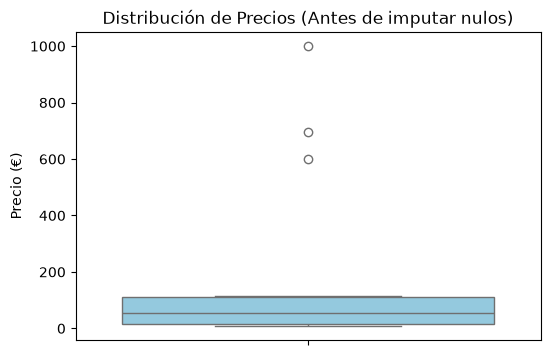

Nulos en 'precio' imputados con la mediana: 55.99€
Nulos en 'categoria' imputados con la moda: Electronica
Nulos en 'ciudad' imputados con la moda: Barcelona


In [16]:
# 3. Estandarización de Texto
df_limpio['categoria'] = df_limpio['categoria'].str.strip().str.title()
logging.info("Categoría estandarizada (strip + title).")

# 4. EDA Visual para decidir imputación de nulos
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_limpio, y='precio', color='skyblue')
plt.title('Distribución de Precios (Antes de imputar nulos)')
plt.ylabel('Precio (€)')
plt.show()

# Imputación: mediana para precio (robusta a outliers) y moda para categoría y ciudad
mediana_precio = df_limpio['precio'].median()
df_limpio['precio'] = df_limpio['precio'].fillna(mediana_precio)
logging.info(f"Nulos en 'precio' imputados con la mediana: {mediana_precio}€")

moda_categoria = df_limpio['categoria'].mode()[0]
df_limpio['categoria'] = df_limpio['categoria'].fillna(moda_categoria)
logging.info(f"Nulos en 'categoria' imputados con la moda: {moda_categoria}")

moda_ciudad = df_limpio['ciudad'].mode()[0]
df_limpio['ciudad'] = df_limpio['ciudad'].fillna(moda_ciudad)
logging.info(f"Nulos en 'ciudad' imputados con la moda: {moda_ciudad}")

## 🔄 FASE 2: TRANSFORMACIÓN - Parte 3: Tipos de Datos y Nuevas Columnas
Corregimos los formatos (especialmente las fechas, que vienen mezcladas) y calculamos el valor total de cada venta (`valor_total`).

In [17]:
# 5. Corrección de Tipos de Datos
# errors='coerce' convierte fechas inválidas en NaT en lugar de romper el código
df_limpio['fecha_compra'] = pd.to_datetime(df_limpio['fecha_compra'], format='mixed', dayfirst=True, errors='coerce')
df_limpio['cantidad'] = df_limpio['cantidad'].astype(int)
logging.info("Tipos de datos convertidos correctamente.")

# 6. Ingeniería de características (Feature Engineering)
df_limpio['valor_total'] = df_limpio['precio'] * df_limpio['cantidad']

logging.info(f"Forma final del dataset: {df_limpio.shape}")
print("\n--- VISTA PREVIA DE DATOS LIMPIOS ---")
display(df_limpio.head())

Tipos de datos convertidos correctamente.
Forma final del dataset: (20, 9)



--- VISTA PREVIA DE DATOS LIMPIOS ---


,id_producto,nombre_producto,categoria,precio,descripcion,fecha_compra,ciudad,cantidad,valor_total
0,1,"Fjallraven - Foldsack No. 1 Backpack, Fits 15 ...",Joyeria,109.95,Your perfect pack for everyday use and walks i...,2023-01-01,Madrid,1,109.95
1,2,Mens Casual Premium Slim Fit T-Shirts,Electronica,22.30,"Slim-fitting style, contrast raglan long sleev...",2023-02-01,Barcelona,2,44.60
2,3,Mens Cotton Jacket,Ropa,55.99,great outerwear jackets for Spring/Autumn/Wint...,2023-03-01,Valencia,1,55.99
3,4,Mens Casual Slim Fit,Electronica,15.99,The color could be slightly different between ...,2023-04-01,Sevilla,3,47.97
4,5,John Hardy Women's Legends Naga Gold & Silver ...,Electronica,695.00,"From our Legends Collection, the Naga was insp...",2023-02-03,Bilbao,2,1390.00


## 📤 FASE 3: CARGA (Load)
Guardamos los datos limpios. Usaremos dos formatos:
1. **CSV:** Universal y legible por humanos.
2. **Parquet:** Formato columnar moderno, mucho más rápido y ligero, estándar en ingeniería de datos actual.

In [18]:
def cargar_datos(df, ruta_base):
    logging.info(f"Iniciando carga de datos...")
    try:
        ruta_csv = ruta_base.replace('.csv', '_limpio.csv')
        ruta_parquet = ruta_base.replace('.csv', '_limpio.parquet')
        
        df.to_csv(ruta_csv, index=False)
        df.to_parquet(ruta_parquet, index=False)
        
        logging.info(f"✅ Carga completada exitosamente en:\n - {ruta_csv}\n - {ruta_parquet}")
    except Exception as e:
        logging.error(f"Error al cargar datos: {e}")
        raise

# Ejecutamos la carga
cargar_datos(df_limpio, 'ventas_api_sucias.csv')
logging.info("=== FIN DEL PROCESO ETL ===")

Iniciando carga de datos...
✅ Carga completada exitosamente en:
 - ventas_api_sucias_limpio.csv
 - ventas_api_sucias_limpio.parquet
=== FIN DEL PROCESO ETL ===


## 🎯 Conclusiones y Próximos Pasos
1. Revisa el archivo `proceso_etl.log` que se ha generado en tu carpeta. ¡Ahí está el historial de tu trabajo!
2. Observa cómo el EDA (el gráfico de caja) nos ayudó a tomar una decisión informada sobre los nulos.
3. **Reto:** Intenta modificar el código para que agrupe las ventas por `categoria` y muestre el `valor_total` acumulado antes de guardar el archivo.

*(Fin de la clase)*